# A Realistic Estimate of the Noise Spectrum

The analysis of the paper filters the data with the noise spectrum that generated them. In real data the spectrum is estimated from neighbouring data, for example as the mean of the periodograms of $N$ blocks of 8 s. Here we analyze noise-only segments with such an estimate and measure how much the likelihood ratio averaged over the population moves, and what this does to the merger rate after a year of data.

The test runs on the GPU and reads the tables of `tables/redshift` (README).

In [1]:
import sys
sys.path.insert(0, '../src')

import time
import numpy as np
from scipy.special import logsumexp
import exmarg.search as search
from exmarg.profiles import profile
import figures_validation as figures

segments = np.load('../data/segments/two_parameters.npz')
sig2 = np.asarray(segments['sig2'], float)
base = {k: segments[k] for k in ('f', 'nu', 'T', 'fmin', 'fmax')}
store = search.load_redshift_store('../tables/redshift', pinned=True)
N_BLOCKS = [32, 128, 512]

## Why the Estimate Biases the Likelihood Ratio

The mean of $N$ periodograms gives $\hat S(f_\nu) = S(f_\nu)\, g_\nu$ with $g_\nu$ distributed as $\Gamma(N, 1/N)$ in every frequency bin. Under noise the filtered data of a template have $\mathbb{E}_0|\mathcal{Z}|^2 = r\, A$, where $A$ is computed with $\hat S$ and

$$ r = \frac{\sum_\nu w_\nu\, g_\nu^{-2}}{\sum_\nu w_\nu\, g_\nu^{-1}}, \qquad w_\nu = \frac{a_\nu^2}{\sigma_\nu^2}. $$

Since $\mathbb{E}[g^{-1}] = N/(N-1)$ and $\mathbb{E}[g^{-2}] = N^2/[(N-1)(N-2)]$, the ratio is $r \simeq N/(N-2)$ on average. The $n$th term of the series then has the noise mean $e^{-y^2 A}(y^2 A\, r)^n/n!$, so $r > 1$ raises the noise mean of the likelihood ratio, and the more the louder the template. Multiplying the estimate by $N/(N-1)$ makes $1/\hat S$ unbiased but leaves $r$ above one, while multiplying it by $N/(N-2)$ brings $r$ to one on average. The draws below check this for templates of the analysis.

In [2]:
rng = np.random.default_rng(7)
nu0 = int(segments['nu'][0])
weights = []
for M in (20.0, 60.0, 200.0):
    nu, f, a, psi = profile(M / 2, M / 2, 0.0, 0.0, float(segments['T']), float(segments['fmin']), float(segments['fmax']), 10410.0)
    w = np.zeros(sig2.size)
    w[np.asarray(nu, int) - nu0] = a ** 2 / sig2[np.asarray(nu, int) - nu0]
    weights.append(w)

print('   N   N/(N-2)   mean r (estimate)   mean r (x N/(N-1))   mean r (x N/(N-2))')
for N in N_BLOCKS:
    r = {1.0: [], N / (N - 1.0): [], N / (N - 2.0): []}
    for k in range(200):
        g = rng.gamma(N, 1.0 / N, sig2.size)
        for c in r:
            for w in weights:
                r[c].append((w @ (c * g) ** -2.0) / (w @ (c * g) ** -1.0))
    print('%4d   %.4f        %.4f              %.4f                %.4f' % (N, N / (N - 2.0), *[np.mean(v) for v in r.values()]))

   N   N/(N-2)   mean r (estimate)   mean r (x N/(N-1))   mean r (x N/(N-2))
  32   1.0667        1.0666              1.0333                1.0000
 128   1.0159        1.0157              1.0078                0.9999
 512   1.0039        1.0041              1.0021                1.0001


## The Test

Noise-only segments are drawn with the true noise variance. Every group of 500 segments shares one estimate, the mean of $N$ periodograms of $N$ independent noise blocks, and the same estimate is used for both detectors because the tables assume equal filter powers. Each group is analyzed four times, with the true spectrum (A), the estimate (B), the estimate times $N/(N-1)$ (C) and the estimate times $N/(N-2)$ (D), so the four analyses see the same noise. The likelihood ratio is averaged over the injected population (GWTC-5 masses and Madau-Dickinson redshifts) for detector-frame total masses from 20 to 400 $M_\odot$. Five groups for each $N$ take about half an hour on one GPU.

In [3]:
masses = np.geomspace(20.0, 400.0, 120)
pop = np.load('../src/exmarg/data/demo_population.npz')
m1 = np.geomspace(4.0, 200.0, 150)
z = np.linspace(0.02, 10.0, 150)
p_m1 = np.interp(m1, pop['m1'], pop['p_m1'], left=0.0, right=0.0)
p_z = np.interp(z, pop['z'], pop['p_z'], left=0.0, right=0.0)
M_det = 2.0 * m1[:, None] * (1.0 + z[None, :])
w = p_m1[:, None] * p_z[None, :] * np.gradient(m1)[:, None] * np.gradient(z)[None, :] * ((M_det >= 20.0) & (M_det <= 400.0))
ln_w = np.log(np.maximum(w / w.sum(), 1e-300))

def lambda_bar(seg):
    bank = search.mass_bank(masses, seg, 'gpu')
    r = search.pe_redshift(seg, bank, store, m1_range=(4.0, 200.0), nm1=150, zmax=10.0, nz=150, resident=True,
                           mdet_range=(20.0, 400.0))
    L = np.where(np.isfinite(r['ln_lambda']), r['ln_lambda'], -np.inf)
    return np.exp(logsumexp(L + ln_w[None], axis=(1, 2)))

GROUPS, PER_GROUP = 5, 500
res = {}
start = time.time()
for N in N_BLOCKS:
    res[N] = {k: [] for k in 'ABCD'}
    for g in range(GROUPS):
        rng = np.random.default_rng(1000 + g)
        seg = dict(base)
        for I in 'HL':
            noise = rng.standard_normal((PER_GROUP, sig2.size)) + 1j * rng.standard_normal((PER_GROUP, sig2.size))
            seg['d_' + I] = (np.sqrt(sig2 / 2.0) * noise).astype(np.complex64)
        blocks = sig2 / 2.0 * (rng.standard_normal((N, sig2.size)) ** 2 + rng.standard_normal((N, sig2.size)) ** 2)
        estimate = blocks.mean(0)
        for k, s2 in (('A', sig2), ('B', estimate), ('C', estimate * N / (N - 1.0)), ('D', estimate * N / (N - 2.0))):
            seg['sig2'] = s2
            res[N][k].append(lambda_bar(seg))
    res[N] = {k: np.concatenate(v) for k, v in res[N].items()}
    print('N = %d done (%.0f s)' % (N, time.time() - start))

N = 32 done (497 s)


N = 128 done (995 s)


N = 512 done (1496 s)


## The Shift of the Noise Mean

The table gives the mean of $\bar\Lambda_{\rm est} - \bar\Lambda_{\rm true}$ over the paired segments, with the error from the scatter between the five groups.

In [4]:
print('   N   estimate          x N/(N-1)          x N/(N-2)')
for N in N_BLOCKS:
    row = []
    for k in 'BCD':
        d = res[N][k] - res[N]['A']
        groups = d.reshape(-1, PER_GROUP).mean(1)
        row.append('%+.4f +- %.4f' % (d.mean(), groups.std(ddof=1) / np.sqrt(groups.size)))
    print('%4d   %s' % (N, '   '.join(row)))

   N   estimate          x N/(N-1)          x N/(N-2)
  32   +0.1075 +- 0.0069   +0.0494 +- 0.0046   +0.0036 +- 0.0032
 128   +0.0224 +- 0.0021   +0.0118 +- 0.0020   +0.0018 +- 0.0019
 512   +0.0052 +- 0.0007   +0.0027 +- 0.0007   +0.0003 +- 0.0007


## One Year of Data

A shift $c$ of the noise mean of $\bar\Lambda_i$ moves the derivative of the mixture likelihood with respect to $\ln R_0$ by $\bar N\, N_{\rm noise}\, c$. Dividing by the $\ln R_0$ element of the Fisher matrix of the simulated year, with the other parameters fixed, gives the shift of $\ln R_0$, which we compare with the width of its posterior in the catalog-informed search. The numbers come from the result files of the year (notebook 4).

In [5]:
year = np.load('../data/year/segment_lnB.npz')
n_noise = year['noise_only_n120'].size
n_merger = year['unresolved_mergers_n120'].size + year['detected_mergers'].size
nbar = n_merger / (n_noise + n_merger)
fisher = float(np.load('../data/year/information.npz')['F_diagonal'][0])
post = np.load('../data/year/posteriors.npz')
sigma = np.log(post['informed_th8_n120'][:, 0]).std()
scale = nbar * n_noise / fisher
print('Nbar = %.4f, noise-only segments %d, Fisher element of ln R0 %.0f, posterior width of ln R0 %.3f' % (nbar, n_noise, fisher, sigma))
print('   N   estimate   x N/(N-1)   x N/(N-2)   (shift of ln R0 in one year)')
for N in N_BLOCKS:
    print('%4d   %s' % (N, '   '.join('%+8.3f' % (scale * (res[N][k] - res[N]['A']).mean()) for k in 'BCD')))

Nbar = 0.0192, noise-only segments 3868835, Fisher element of ln R0 905, posterior width of ln R0 0.160
   N   estimate   x N/(N-1)   x N/(N-2)   (shift of ln R0 in one year)
  32     +8.841     +4.061     +0.295
 128     +1.844     +0.973     +0.146
 512     +0.425     +0.223     +0.024


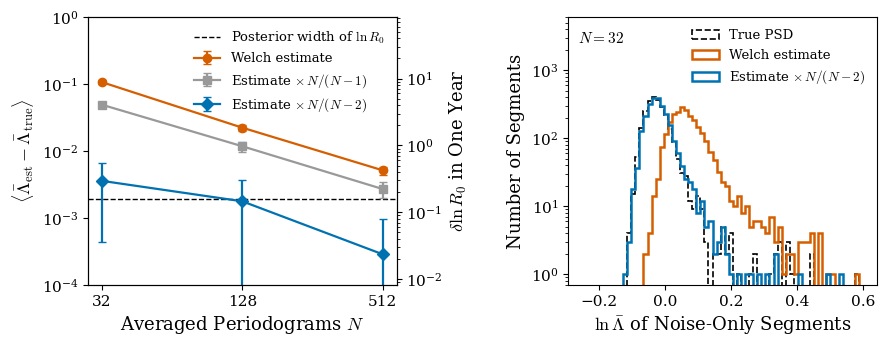

In [6]:
figures.fig_estimated_psd(res, N_BLOCKS, PER_GROUP, scale, sigma)

The estimate of the spectrum moves the noise mean of $\bar\Lambda$ by about $1/N$, which after a year pushes $\ln R_0$ far beyond the width of its posterior unless the estimate is multiplied by $N/(N-2)$. With this factor the shift drops below the width of the posterior. The factor follows from the $\Gamma(N, 1/N)$ distribution of the mean of $N$ periodograms. A median average or overlapping windows change this distribution, and the factor is then computed in the same way from the distribution of that estimate.